# 05 · Production review

Six simulated months from `churn simulate`: monthly cohorts with a growing population shift, a corrupted delivery in April,
and labels that only become visible 30 days after scoring. This notebook reads what the pipeline wrote (reports, prediction logs, model bundles and the MLflow registry)
and reviews whether its decisions were right.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn import config

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

import json

import mlflow

from churn.data.ingest import X_y, load_split
from churn.decision.policy import customer_value, decide
from churn.models.bundle import load_bundle

timeline = [json.loads(line) for line in (config.REPORTS_DIR / "timeline.jsonl").read_text().splitlines()]
promotions = [json.loads(line) for line in (config.REPORTS_DIR / "promotions.jsonl").read_text().splitlines()]

pd.DataFrame({
    "month": [r["as_of"] for r in timeline],
    "shift": [r["shift"] for r in timeline],
    "validation": ["quarantined" if "validation" in r else "ok" for r in timeline],
    "max_feature_psi": [r.get("drift", {}).get("max_feature_psi") for r in timeline],
    "prediction_psi": [r.get("drift", {}).get("prediction_psi") for r in timeline],
    "signals": [", ".join(r["signals"]) or "-" for r in timeline],
    "action": [r["retraining"]["action"] for r in timeline],
    "champion": [f"v{r['champion_before']} -> v{r['champion_after']}" if r["champion_after"] != r["champion_before"] else f"v{r['champion_after']}" for r in timeline],
})

,month,shift,validation,max_feature_psi,prediction_psi,signals,action,champion
0,2026-01-01,0.0,ok,0.042,0.042,-,none,v1
1,2026-02-01,0.0,ok,0.033,0.059,-,none,v1
2,2026-03-01,1.0,ok,0.460,0.744,drift,promoted,v1 -> v2
3,2026-04-01,1.5,quarantined,NaN,NaN,-,none,v2
4,2026-05-01,2.0,ok,0.322,0.547,drift,rejected,v2
5,2026-06-01,2.0,ok,0.202,0.489,drift,promoted,v2 -> v4


## 1. What changed in the population

In [2]:
reference = load_split("train")
cohorts = {p.stem: pd.read_csv(p) for p in sorted(config.PORTFOLIO_DIR.glob("*.csv"))}
mix = pd.DataFrame({
    name: {
        "month-to-month": (df["contract"] == "Month-to-month").mean(),
        "fiber": (df["internet_service"] == "Fiber optic").mean(),
        "electronic check": (df["payment_method"] == "Electronic check").mean(),
        "median monthly $": df["monthly_charges"].median(),
    }
    for name, df in {"train (reference)": reference, **cohorts}.items()
}).T
mix

,month-to-month,fiber,electronic check,median monthly $
train (reference),0.544,0.443,0.341,70.650
2026-01-01,0.548,0.424,0.276,70.150
2026-02-01,0.532,0.460,0.320,70.100
2026-03-01,0.844,0.712,0.580,78.900
2026-04-01,0.880,0.000,0.652,8100.000
2026-05-01,0.800,0.692,0.484,80.525
2026-06-01,0.584,0.388,0.328,61.550


The simulated shift is clear in the cohort mix. By March, 84% of the cohort is month-to-month (54% in training) and 71% is on fiber (44%).
The April row shows the corrupted delivery: a median bill of $8,100 (cents sent as dollars) and 0% fiber (the category was renamed to `"Fiber"`).
Pandera rejected it, so it never reached the model. June is back near the reference mix even though the shift is still 2.0, because the simulation draws without replacement:
over six months 1,047 of the pool's 1,171 month-to-month customers were sampled, so by June there were few left to over-sample.

## 2. Drift, feature by feature

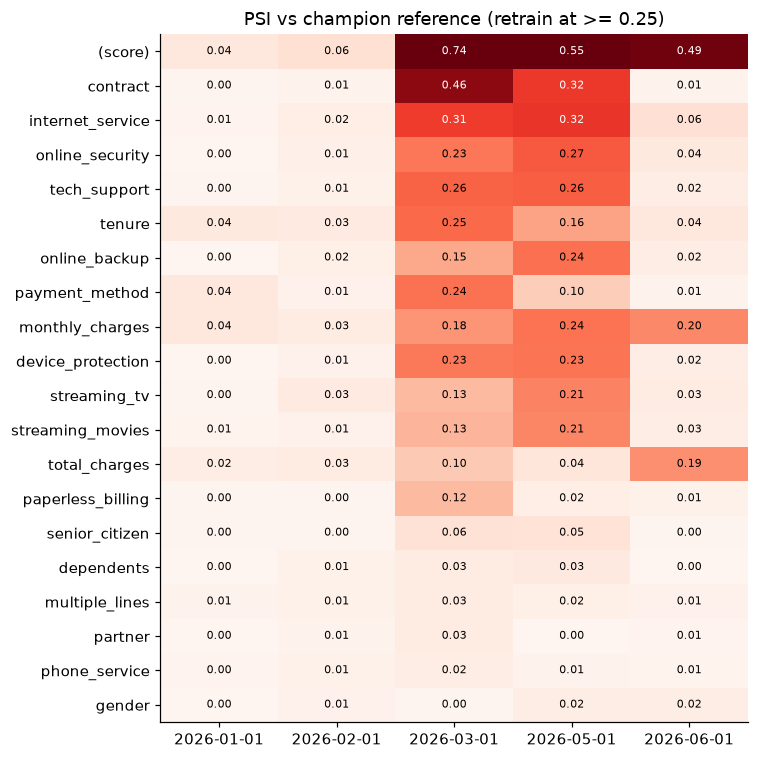

In [3]:
drift = {p.stem.removeprefix("drift_"): json.loads(p.read_text()) for p in sorted(config.REPORTS_DIR.glob("drift_*.json"))}
heat = pd.DataFrame({month: {f["feature"]: f["psi"] for f in report["features"]} for month, report in drift.items()})
heat.loc["(score)"] = [report["prediction_psi"] for report in drift.values()]
heat = heat.loc[heat.max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(heat.clip(upper=0.5), cmap="Reds", aspect="auto", vmin=0, vmax=0.5)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.3 else "black")
ax.set_title(f"PSI vs champion reference (retrain at >= {config.PSI_RETRAIN})")
fig.tight_layout()

The sampling only targets contract, internet service and payment method, but the drift spreads. `contract` (0.46) and `internet_service` (0.32) lead,
and then a block of features that were never targeted also crosses 0.2: online security, tech support, tenure, monthly charges. They move because they're correlated
with the targeted ones (fiber customers pay more, month-to-month customers are newer).
Gender, partner and dependents, which don't correlate with them, stay under 0.035. They work as a natural negative control: the monitor isn't flagging everything.

The score PSI is higher than any single feature (0.74 in March) because the shift hits several correlated drivers at once. Monitoring the score catches combined
shifts that each feature alone would rate as moderate.

## 3. Score distribution

Every valid cohort scored by the same model (v1), so the shift shown is the population's, not a model change.

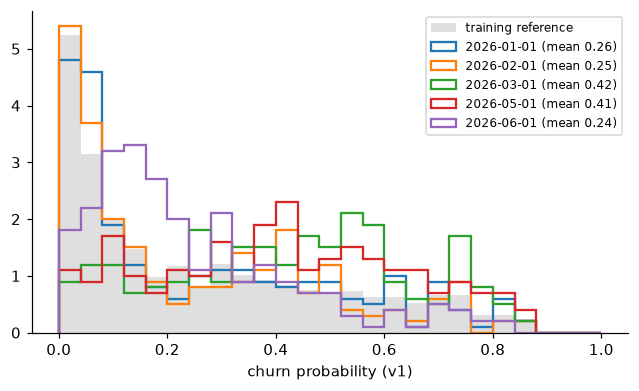

In [4]:
v1 = load_bundle(config.MODELS_DIR / "v1")
ref_scores = v1["model"].predict_proba(pd.read_csv(config.MODELS_DIR / "v1" / "reference.csv"))[:, 1]
fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0, 1, 26)
ax.hist(ref_scores, bins=bins, density=True, histtype="stepfilled", alpha=0.25, color="grey", label="training reference")
valid = [p.stem.removeprefix("scores_") for p in sorted(config.PREDICTIONS_DIR.glob("scores_*.csv"))]
for month in valid:
    scores = v1["model"].predict_proba(cohorts[month][config.FEATURES])[:, 1]
    ax.hist(scores, bins=bins, density=True, histtype="step", lw=1.5, label=f"{month} (mean {scores.mean():.2f})")
ax.set_xlabel("churn probability (v1)")
ax.legend(fontsize=8)

## 4. Labels arrive late

In [5]:
from datetime import date, timedelta

months = [r["as_of"] for r in timeline]
maturity = pd.DataFrame(index=valid, columns=months)
for cohort in valid:
    ready = (date.fromisoformat(cohort) + timedelta(days=config.LABEL_MATURITY_DAYS)).isoformat()
    for as_of in months:
        maturity.loc[cohort, as_of] = "-" if as_of <= cohort else ("matured" if ready <= as_of else "pending")
maturity.index.name = "cohort \\ run date"
maturity

,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01
cohort \ run date,,,,,,
2026-01-01,-,matured,matured,matured,matured,matured
2026-02-01,-,-,pending,matured,matured,matured
2026-03-01,-,-,-,matured,matured,matured
2026-05-01,-,-,-,-,-,matured
2026-06-01,-,-,-,-,-,-


This is the constraint that shapes the whole retraining logic. On March 1st the February cohort is still pending: February has 28 days, so its 30-day window
closes on March 3rd. The drift signal fired that day, but the retrain could only learn from January. Drift tells you today that the inputs changed. Labels tell you a month later whether it mattered.

## 5. Realized performance

,snapshot_date,model_version,rows,gini,gini_ci95,churn_rate,predicted_churn_rate,recall,realized_net_value
0,2026-01-01,1,250,0.516,"[0.403, 0.6356]",0.268,0.260,0.716,9775.86
2,2026-03-01,1,250,0.523,"[0.4016, 0.6374]",0.408,0.421,0.882,19547.16
4,2026-05-01,2,250,0.622,"[0.5224, 0.713]",0.436,0.410,0.917,23367.00


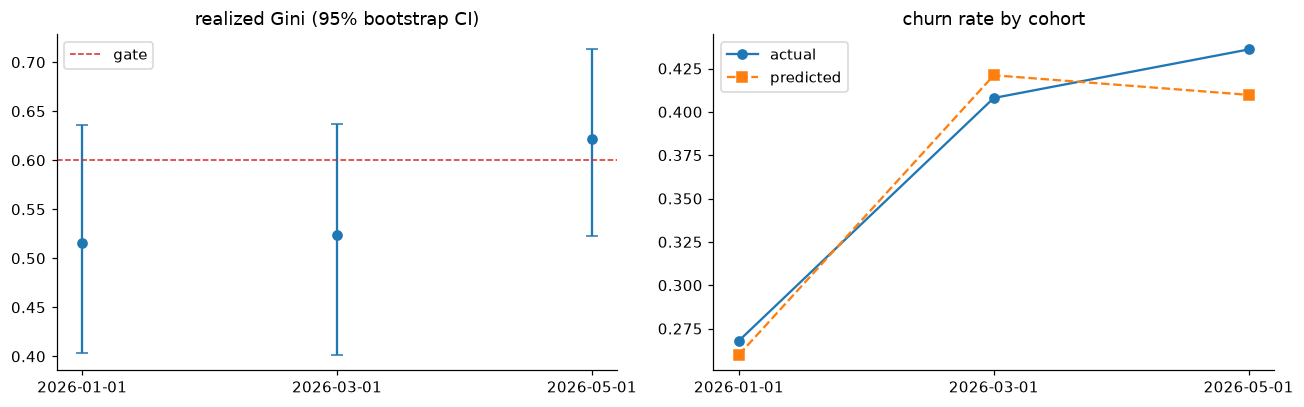

In [6]:
realized = pd.DataFrame([r["realized"] for r in timeline if r["realized"]]).drop_duplicates("snapshot_date")
low, high = realized["gini_ci95"].str[0], realized["gini_ci95"].str[1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].errorbar(realized["snapshot_date"], realized["gini"], yerr=[realized["gini"] - low, high - realized["gini"]], fmt="o", capsize=4)
axes[0].axhline(config.MIN_GINI, color="C3", ls="--", lw=1, label="gate")
axes[0].set_title("realized Gini (95% bootstrap CI)")
axes[0].legend()
axes[1].plot(realized["snapshot_date"], realized["churn_rate"], "o-", label="actual")
axes[1].plot(realized["snapshot_date"], realized["predicted_churn_rate"], "s--", label="predicted")
axes[1].set_title("churn rate by cohort")
axes[1].legend()
fig.tight_layout()
realized[["snapshot_date", "model_version", "rows", "gini", "gini_ci95", "churn_rate", "predicted_churn_rate", "recall", "realized_net_value"]]

- Two of the three point estimates (0.516 and 0.523) are under the 0.60 gate, but no interval lies fully below it. With 250 customers per cohort the realized Gini moves ±0.1
  from sampling alone, so the trigger requires the whole CI below the gate. Performance never fired; drift did.
- **Calibration followed the population.** The actual churn rate rose from 26.8% to 40.8% and 43.6%, and the predicted rate followed (26.0%, 42.1%, 41.0%).
  That's what keeps the expected-value rule valid as the base shifts.
- Realized campaign value grew with the share of high-risk customers ($9.8k → $23.4k per 250 customers).

## 6. Were the promotions real improvements?

The pipeline promotes a challenger if it earns more than the champion on the holdout. That's a single number.
A paired bootstrap on the same holdout customers asks how often the challenger would still win if the holdout had been drawn differently.

In [7]:
holdout = load_split("holdout")
X_h, y_h = X_y(holdout)
value_h = customer_value(X_h)


def customer_gains(version):
    b = load_bundle(config.MODELS_DIR / f"v{version}")
    contact = decide(b["model"].predict_proba(X_h)[:, 1], value_h, b["policy"])
    gain = np.where(y_h == 1, config.OFFER_SUCCESS_RATE * value_h - config.RETENTION_OFFER_COST, -config.RETENTION_OFFER_COST)
    return np.where(contact, gain, 0.0)


rng = np.random.default_rng(config.RANDOM_STATE)
idx = rng.integers(0, len(y_h), size=(2000, len(y_h)))
rows = []
for p in promotions:
    if p["champion"] is None:
        continue
    diff = customer_gains(p["challenger"]["version"]) - customer_gains(p["champion"]["version"])
    boot = diff[idx].sum(axis=1)
    rows.append({
        "challenger": f"v{p['challenger']['version']}",
        "vs champion": f"v{p['champion']['version']}",
        "observed_diff": diff.sum(),
        "ci95_low": np.percentile(boot, 2.5),
        "ci95_high": np.percentile(boot, 97.5),
        "p_challenger_better": (boot > 0).mean(),
        "decision": "promoted" if p["promoted"] else "rejected",
    })
pd.DataFrame(rows).round(3)

,challenger,vs champion,observed_diff,ci95_low,ci95_high,p_challenger_better,decision
0,v2,v1,271.77,-1906.340,2501.365,0.616,promoted
1,v3,v2,-207.12,-2397.688,2089.532,0.401,rejected
2,v4,v2,437.04,-1767.253,2755.998,0.630,promoted


**None of the decisions is statistically solid.** Every 95% interval of the value difference spans zero by roughly ±$2k, and the challengers win in only 40-63% of resamples.
v2 and v4 were promoted on differences ($272 and $437) that are well inside the noise, and v3's rejection ($207) is just as uncertain.

Promotions were harmless here because the candidates are nearly equivalent. But the rule is promoting on noise, the same mistake the retraining trigger already avoids.
The fix is to promote only when `p_challenger_better ≥ 0.95`. Under that rule v1 would still be the champion: compared directly with v1, the challengers win in
62% (v2), 51% (v3) and 78% (v4) of resamples. That's the honest outcome for these data. The retrained models are equivalent to the original, not better.

## 7. The registry

In [8]:
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
client = mlflow.MlflowClient()
versions = sorted(client.search_model_versions(f"name='{config.REGISTERED_MODEL_NAME}'"), key=lambda v: int(v.version))
# search_model_versions doesn't populate aliases; they live on the registered model
aliases = {}
for alias, version in client.get_registered_model(config.REGISTERED_MODEL_NAME).aliases.items():
    aliases.setdefault(str(version), []).append(alias)
pd.DataFrame([
    {
        "version": v.version,
        "aliases": ", ".join(aliases.get(str(v.version), [])) or "-",
        "trigger": v.tags.get("trigger"),
        "promotion": v.tags.get("promotion"),
        "holdout_net_value": float(v.tags.get("holdout_net_value", "nan")),
        "run_id": v.run_id[:8],
    }
    for v in versions
])

,version,aliases,trigger,promotion,holdout_net_value,run_id
0,1,-,initial,promoted,61654.68,c4abdadd
1,2,-,drift,promoted,61926.45,37a7a901
2,3,-,drift,rejected,61719.33,6500edc9
3,4,"challenger, champion",drift,promoted,62363.49,52886b01


In [9]:
runs = mlflow.search_runs(experiment_names=[config.EXPERIMENT_NAME], filter_string="tags.validation_status = 'PASS'")
cols = ["tags.trigger", "params.model_type", "metrics.test_gini", "metrics.test_ece", "metrics.test_net_value", "params.decision_rule"]
runs[cols].sort_values(["tags.trigger", "metrics.test_net_value"], ascending=[True, False]).rename(columns=lambda c: c.split(".", 1)[1]).head(12)

,trigger,model_type,test_gini,test_ece,test_net_value,decision_rule
0,drift,gradient_boosting,0.705,0.034,48921.39,expected_value
1,drift,random_forest,0.706,0.028,48527.64,expected_value
2,drift,logistic_regression,0.707,0.033,48054.18,expected_value
3,drift,gradient_boosting,0.715,0.034,44885.31,expected_value
4,drift,random_forest,0.719,0.041,44638.29,expected_value
5,drift,logistic_regression,0.720,0.038,44012.25,expected_value
8,drift,logistic_regression,0.736,0.043,38785.44,expected_value
6,drift,gradient_boosting,0.722,0.019,38497.62,expected_value
7,drift,random_forest,0.728,0.024,37810.77,expected_value
9,initial,gradient_boosting,0.731,0.021,36003.72,expected_value


## What the six months show

| Check | Result |
|---|---|
| Bad data reaches the model? | No. The corrupted April batch was quarantined |
| Drift detected? | Yes, in the month it started (PSI 0.46 on contract, 0.74 on the score) |
| Retrained on noise? | No for the trigger (CI-based), **yes for promotion** (point estimate) |
| Labels respected? | Yes. Cohorts are used only after their 30-day window |
| Calibration under shift? | Held: predicted vs actual within 1-3 points |
| Every decision traceable? | Yes. Registry versions carry trigger, promotion result and holdout value; aliases point at the champion |

Top priority from this review: put the paired bootstrap from section 6 into `promote_if_better`.